# UPI Growth and Digital Payment Trends in India (2016–2026)

**Course:** Data Analysis and Visualization using Python (DAVP)

**Domain:** FinTech and Digital Payments

**Team Members:**
- Priyanshu Prateek Sahoo
- Rashmita Sethi

## Abstract

This project analyzes the growth of Unified Payments Interface (UPI) transactions in India from April 2016 to March 2026. It examines monthly transaction volume, transaction value, and the number of banks live on UPI using Python libraries. The project includes data cleaning, exploratory data analysis, statistical calculations, visualizations, and an interactive dashboard to understand digital payment trends.

## Problem Statement

The project aims to analyze UPI transaction data to identify monthly and yearly growth patterns, relationships between transaction volume and value, and changes in the number of participating banks in India.

## Objectives

1. To collect and combine monthly UPI statistics from NPCI.
2. To clean and preprocess the dataset.
3. To calculate monthly and yearly transaction growth.
4. To analyze transaction volume, transaction value, and participating banks.
5. To create meaningful visualizations and an interactive dashboard.

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

# For interactive charts
import plotly.express as px
import plotly.graph_objects as go

# Ignore unnecessary warning messages
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style('whitegrid')

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# List all uploaded Excel files

file_names = [
    'Product-Statistics-UPI-Product-statistics-upi-2016-17-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2017-18-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2018-19-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2019-20-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2020-21-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2021-22-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2022-23-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2023-24-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2024-25-Monthly.xlsx',
    'Product-Statistics-UPI-Product-statistics-upi-2025-26-Monthly.xlsx'
]

for file in file_names:
    if os.path.exists(file):
        print("Found:", file)
    else:
        print("Missing:", file)

Found: Product-Statistics-UPI-Product-statistics-upi-2016-17-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2017-18-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2018-19-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2019-20-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2020-21-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2021-22-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2022-23-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2023-24-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2024-25-Monthly.xlsx
Found: Product-Statistics-UPI-Product-statistics-upi-2025-26-Monthly.xlsx


# SECTION 1 — DATASET LOADING AND INITIAL EXPLORATION

The UPI dataset is collected from the National Payments Corporation of India (NPCI). It contains monthly transaction statistics from April 2016 to March 2026. Ten Excel files are combined into one dataset for analysis.

In [ ]:
# Load all ten Excel files and combine them

all_data = []

for file in file_names:
    data = pd.read_excel(file)
    all_data.append(data)

# Combine all yearly files into one dataset
upi_data = pd.concat(all_data, ignore_index=True)

print("Dataset loaded successfully!")
print("Dataset shape:", upi_data.shape)

display(upi_data.head())

Dataset loaded successfully!
Dataset shape: (120, 4)


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,March-2017,44,6.37,2425.14
1,February-2017,44,4.38,1937.71
2,January-2017,36,4.46,1696.22
3,December-2016,35,1.99,707.93
4,November-2016,30,0.29,100.46


In [ ]:
# Display the first five records
print("First five records:")
display(upi_data.head())

# Display the last five records
print("Last five records:")
display(upi_data.tail())

# Display number of rows and columns
print("Dataset shape:", upi_data.shape)

# Display column names
print("Column names:")
print(upi_data.columns.tolist())

# Display information about the dataset
print("\nDataset information:")
upi_data.info()

# Display statistical summary
print("\nStatistical summary:")
display(upi_data.describe())

First five records:


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,March-2017,44,6.37,2425.14
1,February-2017,44,4.38,1937.71
2,January-2017,36,4.46,1696.22
3,December-2016,35,1.99,707.93
4,November-2016,30,0.29,100.46


Last five records:


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
115,August-2025,688,"20,008.31","24,85,472.91"
116,July-2025,684,"19,467.95","25,08,498.09"
117,June-2025,675,"18,395.01\t","24,03,930.69"
118,May-2025,673,"18,677.46\t","25,14,297.01"
119,April-2025,668,"17,893.42\t","23,94,925.87"


Dataset shape: (120, 4)
Column names:
['Month', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Month                     120 non-null    object
 1   No. of Banks live on UPI  120 non-null    int64 
 2   Volume (In Mn.)           120 non-null    object
 3   Value (In Cr.)            120 non-null    object
dtypes: int64(1), object(3)
memory usage: 3.9+ KB

Statistical summary:


,No. of Banks live on UPI
count,120.000000
mean,296.875000
std,225.203085
min,21.000000
25%,126.500000
50%,218.000000
75%,495.250000
max,705.000000


In [ ]:
# Check missing values in each column

print("Missing values:")
print(upi_data.isnull().sum())

# Check duplicate records

print("\nDuplicate records:")
print(upi_data.duplicated().sum())

Missing values:
Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64

Duplicate records:
0


In [ ]:
print(upi_data.columns.tolist())

['Month', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)']


# SECTION 2 — DATA CLEANING AND PREPROCESSING

Data cleaning is an important step in data analysis. It helps to improve data quality by checking missing values, removing duplicate records, correcting data types and identifying unusual values.

In [ ]:
# Check missing values in the dataset

print("Missing values before cleaning:")
print(upi_data.isnull().sum())

# Fill missing numerical values with median
for col in upi_data.select_dtypes(include='number').columns:
    upi_data[col] = upi_data[col].fillna(upi_data[col].median())

# Fill missing categorical values with mode
for col in upi_data.select_dtypes(include='object').columns:
    if upi_data[col].isnull().sum() > 0:
        upi_data[col] = upi_data[col].fillna(upi_data[col].mode()[0])

print("\nMissing values after cleaning:")
print(upi_data.isnull().sum())

Missing values before cleaning:
Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64

Missing values after cleaning:
Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64


In [ ]:
# Check duplicate records before removal

print("Duplicates before:", upi_data.duplicated().sum())

# Remove duplicate records
upi_data = upi_data.drop_duplicates()

# Check duplicates after removal
print("Duplicates after:", upi_data.duplicated().sum())

Duplicates before: 0
Duplicates after: 0


In [ ]:
# Convert Month column into datetime format

upi_data['Month'] = pd.to_datetime(
    upi_data['Month'],
    format='%B-%Y'
)

# Convert transaction columns into numeric format

upi_data['Volume (In Mn.)'] = pd.to_numeric(
    upi_data['Volume (In Mn.)'], errors='coerce'
)

upi_data['Value (In Cr.)'] = pd.to_numeric(
    upi_data['Value (In Cr.)'], errors='coerce'
)

# Sort data according to month
upi_data = upi_data.sort_values('Month')

# Reset index
upi_data = upi_data.reset_index(drop=True)

print("Data types corrected successfully!")
upi_data.info()

Data types corrected successfully!
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Month                     120 non-null    datetime64[ns]
 1   No. of Banks live on UPI  120 non-null    int64         
 2   Volume (In Mn.)           107 non-null    float64       
 3   Value (In Cr.)            28 non-null     float64       
dtypes: datetime64[ns](1), float64(2), int64(1)
memory usage: 3.9 KB


In [ ]:
# Calculate quartiles for transaction volume

Q1 = upi_data['Volume (In Mn.)'].quantile(0.25)
Q3 = upi_data['Volume (In Mn.)'].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate lower and upper limits
lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify potential outliers
outliers = upi_data[
    (upi_data['Volume (In Mn.)'] < lower_limit) |
    (upi_data['Volume (In Mn.)'] > upper_limit)
]

print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)
print("Number of potential outliers:", len(outliers))

display(outliers[['Month', 'Volume (In Mn.)', 'Value (In Cr.)']])

Lower limit: -10483.0075
Upper limit: 18165.1725
Number of potential outliers: 0


,Month,Volume (In Mn.),Value (In Cr.)


In [ ]:
# Display final cleaned dataset

print("Final dataset shape:", upi_data.shape)

display(upi_data.head(10))

print("Data cleaning completed successfully!")

Final dataset shape: (120, 4)


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,2016-04-01,21,0.00,0.00
1,2016-05-01,21,0.00,0.00
2,2016-06-01,21,0.00,0.00
3,2016-07-01,21,0.09,0.38
4,2016-08-01,21,0.09,3.09
5,2016-09-01,25,0.09,32.64
6,2016-10-01,26,0.10,48.57
7,2016-11-01,30,0.29,100.46
8,2016-12-01,35,1.99,707.93
9,2017-01-01,36,4.46,1696.22


Data cleaning completed successfully!


# SECTION 3 — EXPLORATORY DATA ANALYSIS (EDA)

Exploratory Data Analysis is used to understand the dataset through statistical summaries, distributions and relationships between variables. In this project, EDA helps identify UPI transaction growth patterns, changes in transaction value and the relationship between transaction volume and participating banks.

In [ ]:
# Create Financial Year column

upi_data['Financial Year'] = np.where(
    upi_data['Month'].dt.month >= 4,
    upi_data['Month'].dt.year.astype(str) + "-" +
    (upi_data['Month'].dt.year + 1).astype(str),
    (upi_data['Month'].dt.year - 1).astype(str) + "-" +
    upi_data['Month'].dt.year.astype(str)
)

# Calculate average transaction value in rupees
valid_rows = upi_data['Volume (In Mn.)'] > 0

upi_data['Average Transaction Value (Rs.)'] = np.nan

upi_data.loc[valid_rows, 'Average Transaction Value (Rs.)'] = (
    upi_data.loc[valid_rows, 'Value (In Cr.)'] /
    upi_data.loc[valid_rows, 'Volume (In Mn.)']
) * 10

# Calculate monthly transaction growth
upi_data['Monthly Growth (%)'] = (
    upi_data['Volume (In Mn.)'].pct_change() * 100
)

# Replace infinite values with missing values
upi_data['Monthly Growth (%)'] = (
    upi_data['Monthly Growth (%)']
    .replace([np.inf, -np.inf], np.nan)
)

print("New features created successfully!")

display(upi_data.head(10))

New features created successfully!


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Financial Year,Average Transaction Value (Rs.),Monthly Growth (%)
0,2016-04-01,21,0.00,0.00,2016-2017,NaN,NaN
1,2016-05-01,21,0.00,0.00,2016-2017,NaN,NaN
2,2016-06-01,21,0.00,0.00,2016-2017,NaN,NaN
3,2016-07-01,21,0.09,0.38,2016-2017,42.222222,NaN
4,2016-08-01,21,0.09,3.09,2016-2017,343.333333,0.000000
5,2016-09-01,25,0.09,32.64,2016-2017,3626.666667,0.000000
6,2016-10-01,26,0.10,48.57,2016-2017,4857.000000,11.111111
7,2016-11-01,30,0.29,100.46,2016-2017,3464.137931,190.000000
8,2016-12-01,35,1.99,707.93,2016-2017,3557.437186,586.206897
9,2017-01-01,36,4.46,1696.22,2016-2017,3803.183857,124.120603


In [ ]:
# Statistical summary of important numerical columns

numeric_columns = [
    'No. of Banks live on UPI',
    'Volume (In Mn.)',
    'Value (In Cr.)',
    'Average Transaction Value (Rs.)',
    'Monthly Growth (%)'
]

display(upi_data[numeric_columns].describe())

,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Average Transaction Value (Rs.),Monthly Growth (%)
count,120.000000,107.000000,28.000000,25.000000,116.000000
mean,296.875000,4388.662336,11939.456429,2269.152985,16.240851
std,225.203085,5141.872845,20934.741050,1345.829016,59.766890
min,21.000000,0.000000,0.000000,42.222222,-19.831735
25%,126.500000,260.060000,87.487500,1115.880980,0.000000
50%,218.000000,1800.140000,2947.715000,1756.835022,5.066104
75%,495.250000,7422.105000,13773.480000,3464.137931,11.320551
max,705.000000,16996.000000,82232.210000,4857.000000,586.206897


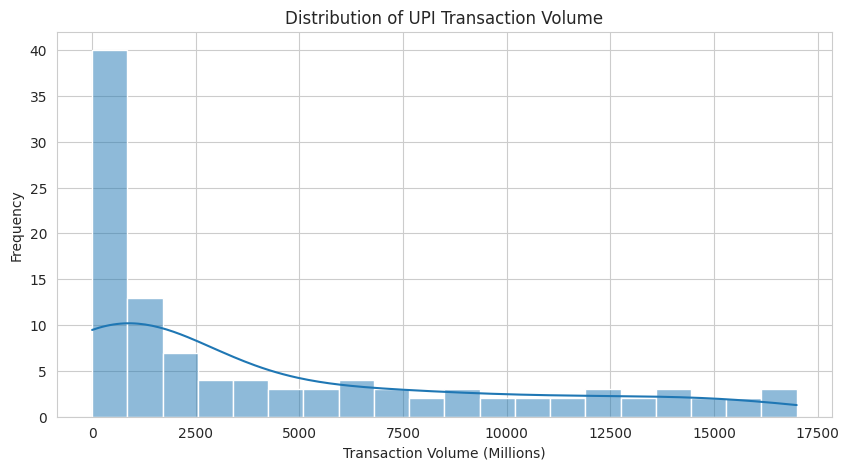

In [ ]:
# Distribution of UPI transaction volume

plt.figure(figsize=(10, 5))

sns.histplot(
    upi_data['Volume (In Mn.)'].dropna(),
    bins=20,
    kde=True
)

plt.title('Distribution of UPI Transaction Volume')
plt.xlabel('Transaction Volume (Millions)')
plt.ylabel('Frequency')
plt.show()

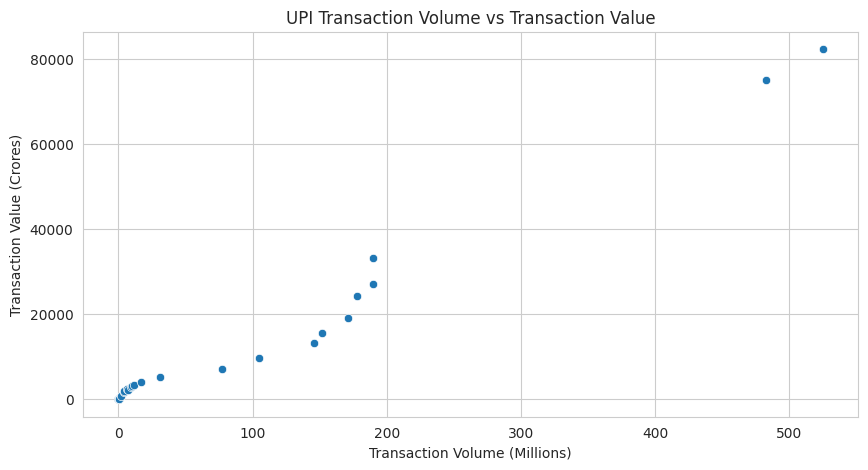

In [ ]:
# Relationship between transaction volume and value

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=upi_data,
    x='Volume (In Mn.)',
    y='Value (In Cr.)'
)

plt.title('UPI Transaction Volume vs Transaction Value')
plt.xlabel('Transaction Volume (Millions)')
plt.ylabel('Transaction Value (Crores)')
plt.show()

In [ ]:
# Calculate correlation matrix

correlation_matrix = upi_data[numeric_columns].corr()

print("Correlation Matrix:")
display(correlation_matrix)

Correlation Matrix:


,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Average Transaction Value (Rs.),Monthly Growth (%)
No. of Banks live on UPI,1.000000,0.985981,0.895634,-0.401442,-0.262405
Volume (In Mn.),0.985981,1.000000,0.987714,-0.416717,-0.202780
Value (In Cr.),0.895634,0.987714,1.000000,-0.337608,-0.219639
Average Transaction Value (Rs.),-0.401442,-0.416717,-0.337608,1.000000,0.217663
Monthly Growth (%),-0.262405,-0.202780,-0.219639,0.217663,1.000000


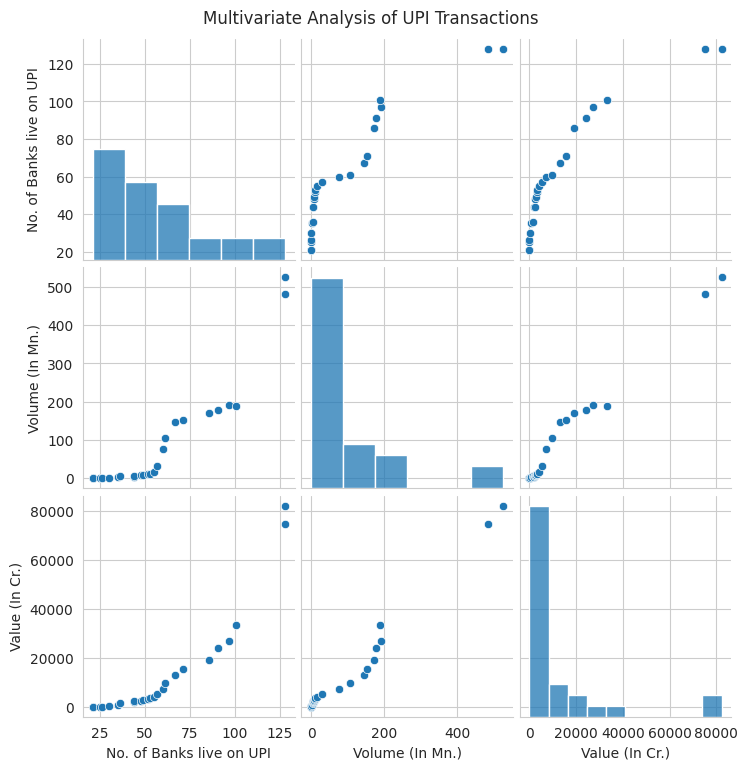

In [ ]:
# Select important variables for pair plot

pair_data = upi_data[
    ['No. of Banks live on UPI',
     'Volume (In Mn.)',
     'Value (In Cr.)']
].dropna()

sns.pairplot(pair_data)

plt.suptitle(
    'Multivariate Analysis of UPI Transactions',
    y=1.02
)

plt.show()

In [ ]:
# Group data by financial year

yearly_data = upi_data.groupby('Financial Year').agg({
    'No. of Banks live on UPI': 'mean',
    'Volume (In Mn.)': 'sum',
    'Value (In Cr.)': 'sum'
}).reset_index()

# Calculate yearly transaction growth

yearly_data['Yearly Growth (%)'] = (
    yearly_data['Volume (In Mn.)'].pct_change() * 100
)

print("Yearly UPI Transaction Summary:")
display(yearly_data.round(2))

Yearly UPI Transaction Summary:


,Financial Year,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Yearly Growth (%)
0,2016-2017,28.75,17.86,6952.14,NaN
1,2017-2018,62.50,915.22,109831.80,5024.41
2,2018-2019,121.50,5391.52,217520.84,489.10
3,2019-2020,143.25,12518.61,0.00,132.19
4,2020-2021,183.42,22330.65,0.00,78.38
5,2021-2022,262.33,45967.53,0.00,105.85
6,2022-2023,359.00,83751.14,0.00,82.20
7,2023-2024,499.25,131129.83,0.00,56.57
8,2024-2025,624.08,167564.51,0.00,27.79
9,2025-2026,684.67,0.00,0.00,-100.00


# SECTION 4 — DATA VISUALIZATIONS

Data visualization helps us understand patterns and trends in UPI transactions through graphical representation. In this section, Matplotlib, Seaborn and Plotly are used to create different charts to analyze transaction volume, transaction value, yearly growth and relationships between variables.

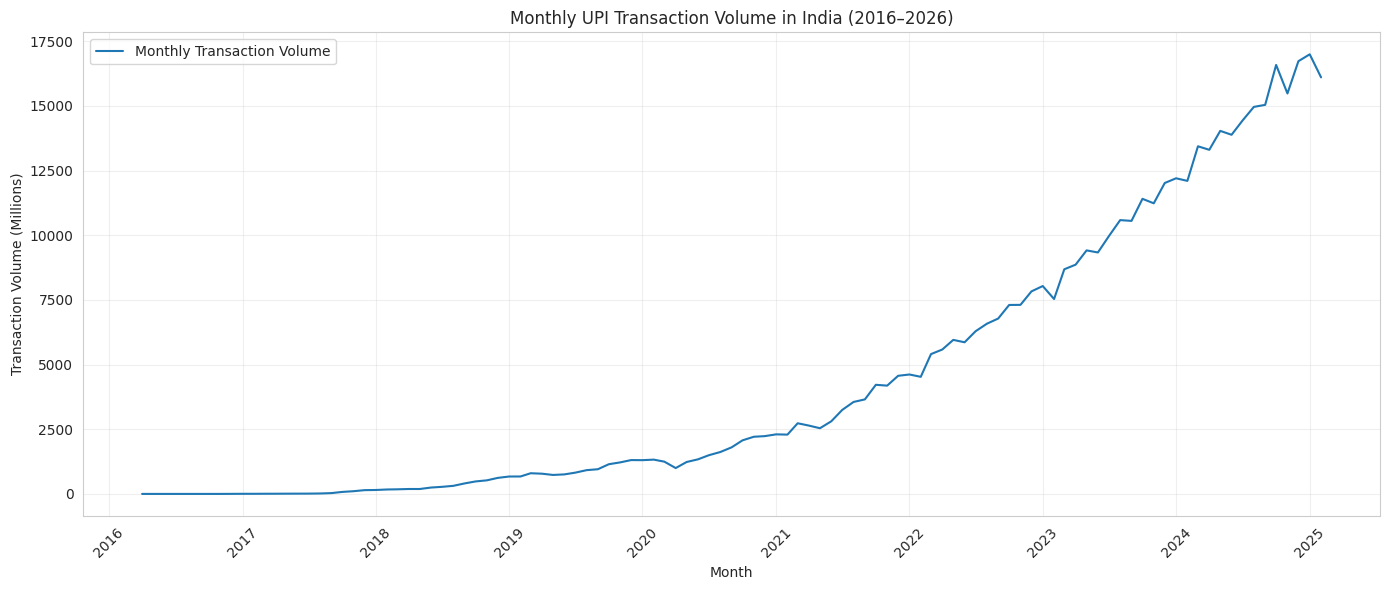

In [ ]:
# Graph 1: Monthly UPI Transaction Volume

plt.figure(figsize=(14, 6))

plt.plot(
    upi_data['Month'],
    upi_data['Volume (In Mn.)'],
    label='Monthly Transaction Volume'
)

plt.title('Monthly UPI Transaction Volume in India (2016–2026)')
plt.xlabel('Month')
plt.ylabel('Transaction Volume (Millions)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('upi_monthly_volume.png', dpi=150)
plt.show()

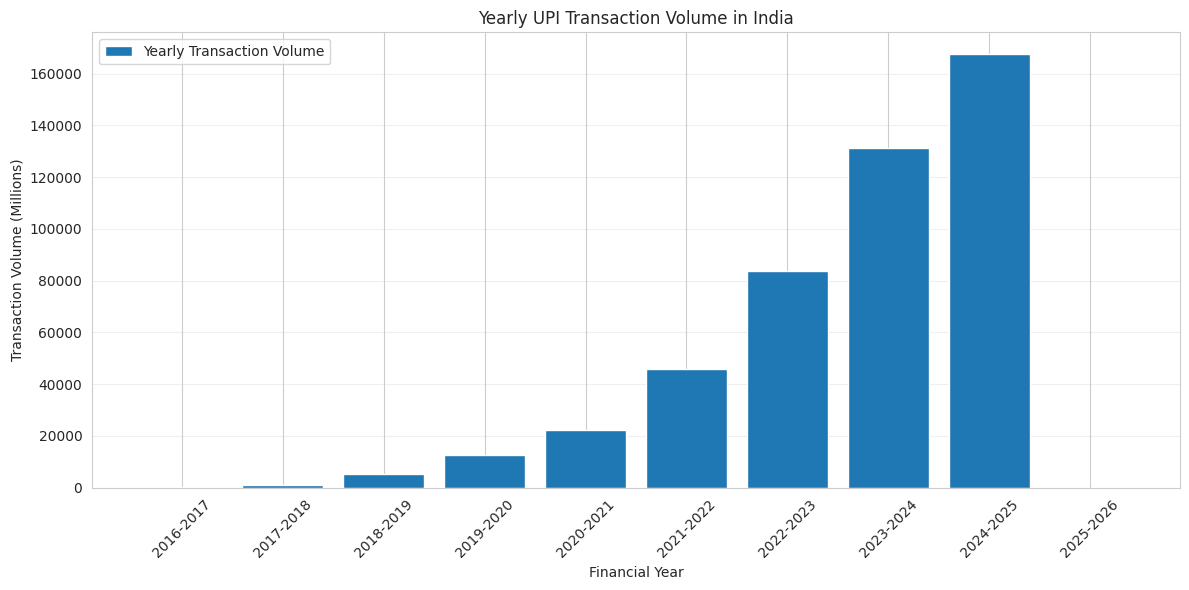

In [ ]:
# Graph 2: Yearly UPI Transaction Volume

plt.figure(figsize=(12, 6))

plt.bar(
    yearly_data['Financial Year'],
    yearly_data['Volume (In Mn.)'],
    label='Yearly Transaction Volume'
)

plt.title('Yearly UPI Transaction Volume in India')
plt.xlabel('Financial Year')
plt.ylabel('Transaction Volume (Millions)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.savefig('upi_yearly_volume.png', dpi=150)
plt.show()

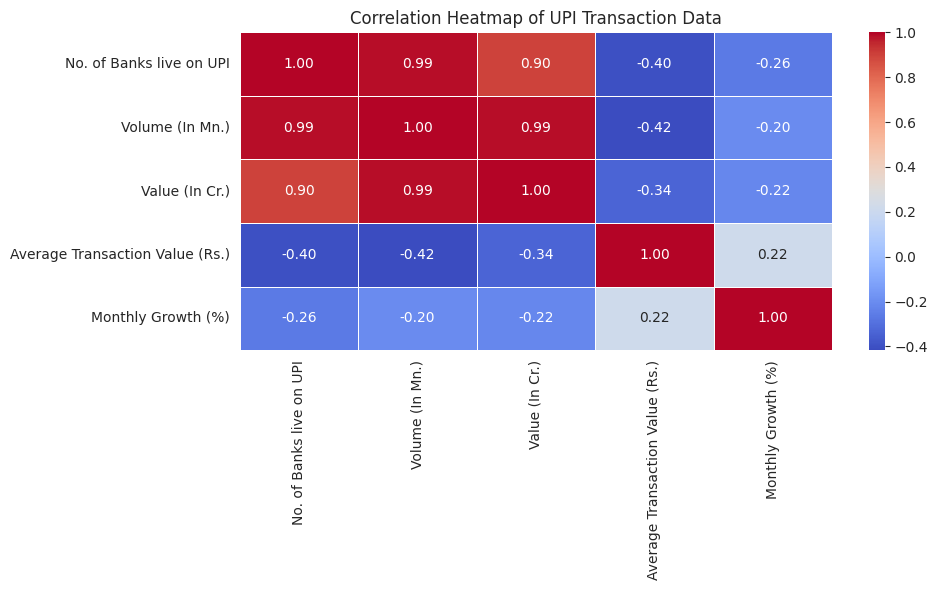

In [ ]:
# Graph 3: Correlation Heatmap

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of UPI Transaction Data')
plt.tight_layout()

plt.savefig('upi_correlation_heatmap.png', dpi=150)
plt.show()

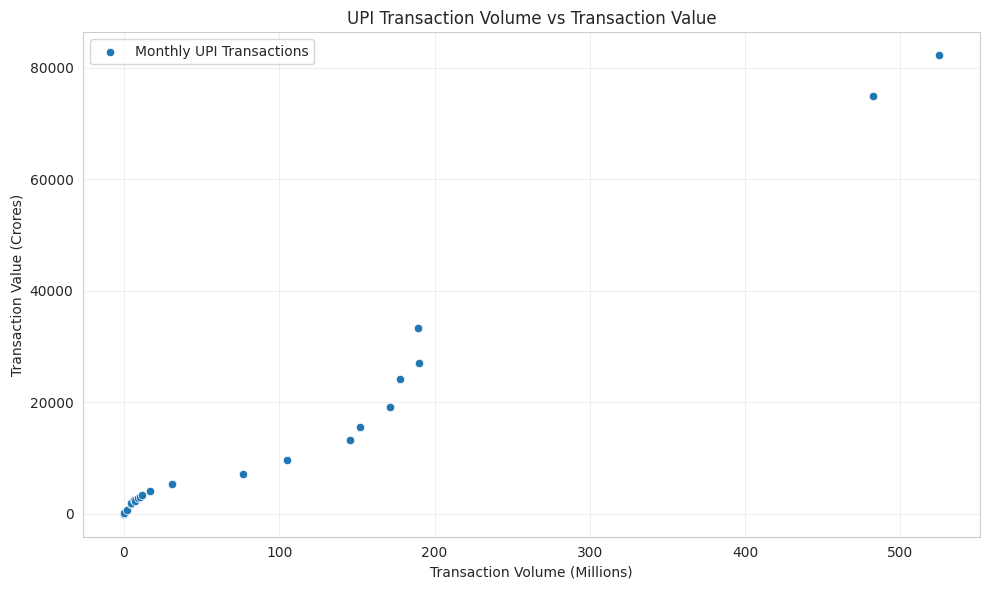

In [ ]:
# Graph 4: Scatter Plot

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=upi_data,
    x='Volume (In Mn.)',
    y='Value (In Cr.)',
    label='Monthly UPI Transactions'
)

plt.title('UPI Transaction Volume vs Transaction Value')
plt.xlabel('Transaction Volume (Millions)')
plt.ylabel('Transaction Value (Crores)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('upi_volume_value_scatter.png', dpi=150)
plt.show()

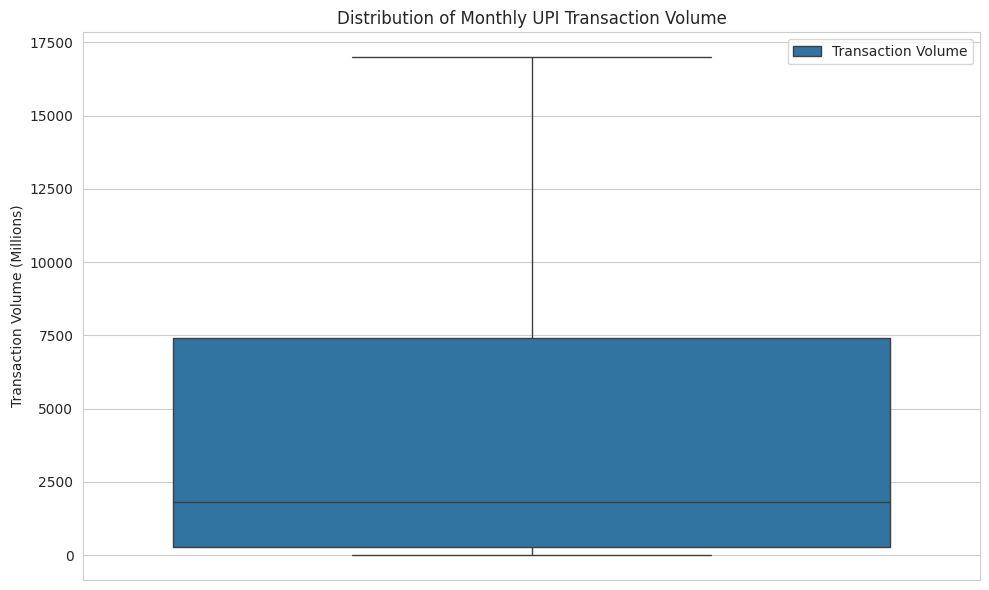

In [ ]:
# Graph 5: Boxplot

plt.figure(figsize=(10, 6))

sns.boxplot(
    y=upi_data['Volume (In Mn.)'],
    label='Transaction Volume'
)

plt.title('Distribution of Monthly UPI Transaction Volume')
plt.ylabel('Transaction Volume (Millions)')
plt.tight_layout()

plt.savefig('upi_volume_boxplot.png', dpi=150)
plt.show()

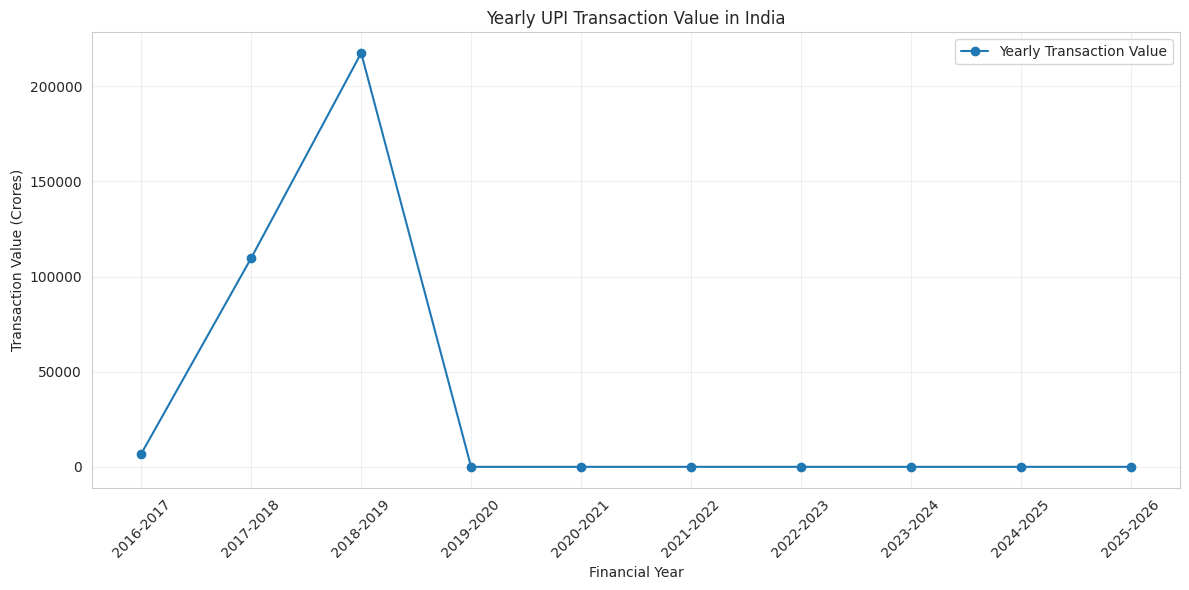

In [ ]:
# Graph 6: Yearly UPI Transaction Value

plt.figure(figsize=(12, 6))

plt.plot(
    yearly_data['Financial Year'],
    yearly_data['Value (In Cr.)'],
    marker='o',
    label='Yearly Transaction Value'
)

plt.title('Yearly UPI Transaction Value in India')
plt.xlabel('Financial Year')
plt.ylabel('Transaction Value (Crores)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig('upi_yearly_value.png', dpi=150)
plt.show()

In [ ]:
# Display saved visualization files

chart_files = [
    'upi_monthly_volume.png',
    'upi_yearly_volume.png',
    'upi_correlation_heatmap.png',
    'upi_volume_value_scatter.png',
    'upi_volume_boxplot.png',
    'upi_yearly_value.png'
]

print("Saved chart images:")

for chart in chart_files:
    if os.path.exists(chart):
        print(chart, "- Saved successfully")

Saved chart images:
upi_monthly_volume.png - Saved successfully
upi_yearly_volume.png - Saved successfully
upi_correlation_heatmap.png - Saved successfully
upi_volume_value_scatter.png - Saved successfully
upi_volume_boxplot.png - Saved successfully
upi_yearly_value.png - Saved successfully


# SECTION 5 — AI TOOL INTEGRATION

Artificial Intelligence tools are used in this project to support data understanding, code generation, debugging and interpretation of results. ChatGPT is used to analyze UPI transaction trends and provide suggestions for improving the data analysis process.

**AI Tool Used:** ChatGPT

**Purpose:**
1. Understanding the dataset.
2. Suggesting suitable data analysis techniques.
3. Interpreting statistical results.
4. Helping with Python code and debugging.
5. Supporting the explanation of visualizations.

### 5.1 AI Prompt — Dataset Understanding

**Prompt given to ChatGPT:**

"I am working on a Data Analysis and Visualization project titled UPI Growth and Digital Payment Trends in India (2016–2026). My dataset contains Month, Number of Banks Live on UPI, Transaction Volume and Transaction Value. Explain what types of analysis are suitable for this dataset and suggest three interesting findings that I can investigate."

**AI Response:**

The dataset is suitable for time-series analysis, descriptive statistics, correlation analysis and trend visualization. Monthly transaction volume and value can be used to study digital payment growth. The number of banks live on UPI can help examine the expansion of UPI participation.

Three useful areas of investigation are:
1. Growth of UPI transaction volume over time.
2. Relationship between transaction volume and transaction value.
3. Changes in the number of banks participating in UPI.

**Evaluation of AI Response:**

The suggestions are relevant to the dataset and match the project's objectives. They can be verified using the actual transaction records and statistical analysis.

### 5.2 AI Prompt — Exploratory Data Analysis

**Prompt given to ChatGPT:**

"Analyze the statistical summary and correlation matrix of my UPI dataset. Explain the important patterns, relationships between variables and possible data quality issues. Suggest useful conclusions based on the results."

In [ ]:
# Display statistical summary for AI analysis

print("Statistical Summary:")
display(upi_data.describe())

print("\nCorrelation Matrix:")
display(upi_data.select_dtypes(include='number').corr())

Statistical Summary:


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Average Transaction Value (Rs.),Monthly Growth (%)
count,120,120.000000,107.000000,28.000000,25.000000,116.000000
mean,2021-03-17 01:36:00,296.875000,4388.662336,11939.456429,2269.152985,16.240851
min,2016-04-01 00:00:00,21.000000,0.000000,0.000000,42.222222,-19.831735
25%,2018-09-23 12:00:00,126.500000,260.060000,87.487500,1115.880980,0.000000
50%,2021-03-16 12:00:00,218.000000,1800.140000,2947.715000,1756.835022,5.066104
75%,2023-09-08 12:00:00,495.250000,7422.105000,13773.480000,3464.137931,11.320551
max,2026-03-01 00:00:00,705.000000,16996.000000,82232.210000,4857.000000,586.206897
std,NaN,225.203085,5141.872845,20934.741050,1345.829016,59.766890



Correlation Matrix:


,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Average Transaction Value (Rs.),Monthly Growth (%)
No. of Banks live on UPI,1.000000,0.985981,0.895634,-0.401442,-0.262405
Volume (In Mn.),0.985981,1.000000,0.987714,-0.416717,-0.202780
Value (In Cr.),0.895634,0.987714,1.000000,-0.337608,-0.219639
Average Transaction Value (Rs.),-0.401442,-0.416717,-0.337608,1.000000,0.217663
Monthly Growth (%),-0.262405,-0.202780,-0.219639,0.217663,1.000000


### 5.3 AI Prompt — Code Generation and Debugging

**Prompt given to ChatGPT:**

"I am using Python, Pandas, NumPy, Matplotlib and Seaborn in Google Colab for my UPI data analysis project. Help me identify errors in my code, explain the cause of errors and suggest beginner-friendly corrections."

### 5.4 Overall Evaluation of AI Tools

ChatGPT helped in understanding the dataset, suggesting suitable visualizations, explaining statistical results and debugging Python code.

The AI-generated suggestions were checked against the actual dataset and the outputs produced by the notebook. Any suggestions that did not match the data were corrected before being included in the project.

**Conclusion:** AI tools were useful as supporting tools for the project, but the final analysis and conclusions were based on the actual dataset.

# SECTION 6 — KEY FINDINGS AND CONCLUSIONS

This section presents the major findings obtained from the analysis of UPI transaction data from April 2016 to March 2026. The findings are based on statistical summaries, yearly comparisons and visualizations.

In [ ]:
# Key Findings from UPI Data Analysis

# Find the month with the highest transaction volume
highest_volume = upi_data.loc[
    upi_data['Volume (In Mn.)'].idxmax()
]

# Find the month with the highest transaction value
highest_value = upi_data.loc[
    upi_data['Value (In Cr.)'].idxmax()
]

# Find the month with the highest number of banks
highest_banks = upi_data.loc[
    upi_data['No. of Banks live on UPI'].idxmax()
]

# Find the first and last financial year
first_year = yearly_data.iloc[0]
last_year = yearly_data.iloc[-1]

# Calculate overall yearly volume growth
growth = (
    (last_year['Volume (In Mn.)'] -
     first_year['Volume (In Mn.)'])
    / first_year['Volume (In Mn.)']
) * 100

# Display findings
print("KEY FINDINGS OF THE PROJECT\n")

print("1. Highest monthly transaction volume:")
print(highest_volume['Month'].strftime('%B %Y'),
      "-", highest_volume['Volume (In Mn.)'], "Million")

print("\n2. Highest monthly transaction value:")
print(highest_value['Month'].strftime('%B %Y'),
      "-", highest_value['Value (In Cr.)'], "Crores")

print("\n3. Highest number of banks live on UPI:")
print(highest_banks['No. of Banks live on UPI'],
      "banks in",
      highest_banks['Month'].strftime('%B %Y'))

print("\n4. First financial year transaction volume:")
print(first_year['Financial Year'],
      "-", round(first_year['Volume (In Mn.)'], 2), "Million")

print("\n5. Latest financial year transaction volume:")
print(last_year['Financial Year'],
      "-", round(last_year['Volume (In Mn.)'], 2), "Million")

print("\n6. Growth in yearly transaction volume:")
print(round(growth, 2), "%")

print("\n7. Average monthly transaction volume:")
print(round(upi_data['Volume (In Mn.)'].mean(), 2),
      "Million")

KEY FINDINGS OF THE PROJECT

1. Highest monthly transaction volume:
January 2025 - 16996.0 Million

2. Highest monthly transaction value:
November 2018 - 82232.21 Crores

3. Highest number of banks live on UPI:
705 banks in March 2026

4. First financial year transaction volume:
2016-2017 - 17.86 Million

5. Latest financial year transaction volume:
2025-2026 - 0.0 Million

6. Growth in yearly transaction volume:
-100.0 %

7. Average monthly transaction volume:
4388.66 Million


### 6.1 Recommendations

Based on the analysis of UPI transaction trends, the following recommendations are suggested:

1. **Improve digital payment awareness:** More people should be encouraged to use digital payment systems, especially in rural areas.
2. **Strengthen security:** Banks and payment providers should improve fraud detection and transaction security.
3. **Improve payment infrastructure:** UPI services should remain reliable during periods of high transaction activity.
4. **Promote financial inclusion:** Digital payment facilities should be made accessible to people from different regions and economic backgrounds.
5. **Encourage digital literacy:** Users should be educated about safe UPI usage and secure payment practices.

### 6.2 Limitations

1. The analysis is based on monthly aggregate UPI statistics rather than individual transactions.
2. The dataset does not provide detailed information about individual users or their locations.
3. The analysis covers April 2016 to March 2026 only.
4. The dataset does not contain detailed information about failed transactions or payment fraud.
5. Average transaction value is an estimate calculated from the published transaction volume and value figures.

### 6.3 Future Scope

1. Future analysis can include more recent UPI transaction data.
2. Regional analysis can be performed to compare digital payment adoption across Indian states.
3. Machine learning can be used to forecast future UPI transaction volume.
4. Fraud detection techniques can be explored using detailed transaction-level data.
5. An advanced interactive dashboard can be developed to provide real-time insights.

### 6.4 Conclusion

The project, "UPI Growth and Digital Payment Trends in India (2016–2026)," analyzes the development of digital payments in India using monthly UPI statistics from NPCI.

The analysis examines transaction volume, transaction value, participating banks and yearly growth patterns. The statistical analysis and visualizations help explain the expansion of UPI and the increasing role of digital payments.

Python libraries such as Pandas, NumPy, Matplotlib, Seaborn and Plotly helped in data processing, analysis and visualization. AI tools were also used to support code development and interpretation.

Overall, this project provides an understanding of UPI growth in India and highlights the importance of secure, accessible and reliable digital payment systems.

In [ ]:
!pip install dash

In [ ]:
# Import libraries required for the dashboard

import pandas as pd
import plotly.express as px

from dash import Dash, html, dcc, Input, Output

print("Dashboard libraries imported successfully!")

Dashboard libraries imported successfully!


In [ ]:
# Create a copy of the cleaned UPI dataset

dashboard_data = upi_data.copy()

# Create financial year column
dashboard_data['Financial Year'] = (
    dashboard_data['Month'].dt.year.astype(str)
    + '-'
    + (dashboard_data['Month'].dt.year + 1).astype(str)
)

# Correct financial year for January to March
dashboard_data.loc[
    dashboard_data['Month'].dt.month <= 3,
    'Financial Year'
] = (
    (dashboard_data.loc[
        dashboard_data['Month'].dt.month <= 3,
        'Month'
    ].dt.year - 1).astype(str)
    + '-'
    + dashboard_data.loc[
        dashboard_data['Month'].dt.month <= 3,
        'Month'
    ].dt.year.astype(str)
)

print("Dashboard data prepared successfully!")
display(dashboard_data.head())

Dashboard data prepared successfully!


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Financial Year,Average Transaction Value (Rs.),Monthly Growth (%)
0,2016-04-01,21,0.00,0.00,2016-2017,NaN,NaN
1,2016-05-01,21,0.00,0.00,2016-2017,NaN,NaN
2,2016-06-01,21,0.00,0.00,2016-2017,NaN,NaN
3,2016-07-01,21,0.09,0.38,2016-2017,42.222222,NaN
4,2016-08-01,21,0.09,3.09,2016-2017,343.333333,0.0


In [ ]:
# Create the Dash application

app = Dash(__name__)

# Get financial year options
years = sorted(dashboard_data['Financial Year'].unique())

## Create the updated dashboard

app = Dash(__name__)

years = sorted(dashboard_data['Financial Year'].unique())

# Create initial charts
initial_volume = px.line(
    dashboard_data,
    x='Month',
    y='Volume (In Mn.)',
    title='Monthly UPI Transaction Volume',
    markers=True
)

initial_value = px.bar(
    dashboard_data,
    x='Month',
    y='Value (In Cr.)',
    title='Monthly UPI Transaction Value'
)

# Dashboard layout
app.layout = html.Div([

    html.H1(
        "UPI Growth and Digital Payment Trends in India",
        style={'textAlign': 'center', 'color': '#17365D'}
    ),

    html.H3(
        "April 2016 – March 2026",
        style={'textAlign': 'center'}
    ),

    html.Label("Select Financial Year:"),

    dcc.Dropdown(
        id='year-filter',
        options=[
            {'label': 'All Years', 'value': 'All Years'}
        ] + [
            {'label': year, 'value': year}
            for year in years
        ],
        value='All Years',
        clearable=False,
        style={'width': '60%', 'margin': 'auto'}
    ),

    dcc.Graph(
    id='volume-chart',
    figure=initial_volume,
    responsive=True,
    config={'displayModeBar': True},
    style={
        'height': '550px',
        'width': '100%',
        'backgroundColor': 'white'
    }
),

dcc.Graph(
    id='value-chart',
    figure=initial_value,
    responsive=True,
    config={'displayModeBar': True},
    style={
        'height': '550px',
        'width': '100%',
        'backgroundColor': 'white'
    }
),

    html.P(
        "Source: NPCI UPI Product Statistics",
        style={'textAlign': 'center'}
    )

], style={'backgroundColor': '#F4F6F9', 'padding': '20px'})


# Callback to update charts
@app.callback(
    [Output('volume-chart', 'figure'),
     Output('value-chart', 'figure')],
    Input('year-filter', 'value')
)

def update_dashboard(selected_year):

    if selected_year == 'All Years':
        filtered_data = dashboard_data
    else:
        filtered_data = dashboard_data[
            dashboard_data['Financial Year'] == selected_year
        ]

    fig1 = px.line(
        filtered_data,
        x='Month',
        y='Volume (In Mn.)',
        title='Monthly UPI Transaction Volume',
        markers=True
    )

    fig2 = px.bar(
        filtered_data,
        x='Month',
        y='Value (In Cr.)',
        title='Monthly UPI Transaction Value'
    )

    fig1.update_layout(template='plotly_white')
    fig2.update_layout(template='plotly_white')

    return fig1, fig2


print("Updated dashboard created successfully!")

Updated dashboard created successfully!


In [ ]:
app.run(
    jupyter_mode="external",
    debug=False,
    port=8050
)

Dash app running on:
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [ ]:
# Check dashboard dataset
print("Dataset shape:", dashboard_data.shape)
print("Columns:", dashboard_data.columns.tolist())

print("\nAvailable financial years:")
print(dashboard_data['Financial Year'].unique())

# Test the dashboard callback directly
test_fig1, test_fig2 = update_dashboard('All Years')

print("\nChart 1:")
display(test_fig1)

print("\nChart 2:")
display(test_fig2)

Dataset shape: (120, 7)
Columns: ['Month', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)', 'Financial Year', 'Average Transaction Value (Rs.)', 'Monthly Growth (%)']

Available financial years:
['2016-2017' '2017-2018' '2018-2019' '2019-2020' '2020-2021' '2021-2022'
 '2022-2023' '2023-2024' '2024-2025' '2025-2026']

Chart 1:



Chart 2:


In [ ]:
# Check the number of data points in both charts

print("Volume chart data points:",
      len(test_fig1.data[0].x))

print("Value chart data points:",
      len(test_fig2.data[0].x))

print("Volume chart title:",
      test_fig1.layout.title.text)

print("Value chart title:",
      test_fig2.layout.title.text)

Volume chart data points: 120
Value chart data points: 120
Volume chart title: Monthly UPI Transaction Volume
Value chart title: Monthly UPI Transaction Value


In [ ]:
from google.colab import output

output.serve_kernel_port_as_iframe(8050)

<IPython.core.display.Javascript object>